# Foundations worksheet: executable task support

Independent worked examples. Keyboard drills and learner-owned reflections remain pending; no personal UI participation is claimed.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, json, time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
OUT = Path('../Worksheet-OutputFiles')
OUT.mkdir(exist_ok=True)
sys.path.insert(0, str(OUT.resolve()))

## Section 1: Write, Run, and Reload

In [2]:
%%writefile ../Worksheet-OutputFiles/tools.py
def shout(text):
    return text.upper() + '!'


Overwriting ../Worksheet-OutputFiles/tools.py


In [3]:
%load_ext autoreload
%autoreload 2
import tools
print(tools.shout('hello'))
assert tools.shout('hello') == 'HELLO!'
# Ensure the next source change has a later timestamp on coarse filesystems.
time.sleep(1.1)

HELLO!


In [4]:
%%writefile ../Worksheet-OutputFiles/tools.py
def shout(text):
    return text.upper() + '!!!'


Overwriting ../Worksheet-OutputFiles/tools.py


In [5]:
print(tools.shout('hello'))
assert tools.shout('hello') == 'HELLO!!!'

HELLO!!!


## Section 2: Break It, Then Fix It

This is an isolated programmatic execution-order demonstration. The keyboard-only drill remains pending.

In [6]:
broken_order = ['print(area)', 'width, height = 4, 5', 'area = width * height']
namespace = {}
try:
    exec(broken_order[0], namespace)
except NameError as error:
    print(type(error).__name__, str(error))
# An out-of-order run works by creating the dependencies first.
for index in [1, 2, 0]:
    exec(broken_order[index], namespace)
# A fresh namespace has no leftover area.
try:
    exec(broken_order[0], {})
except NameError:
    print('Fresh state exposes the incorrect saved order')
fixed_order = [broken_order[i] for i in [1, 2, 0]]
fresh = {}
for statement in fixed_order:
    exec(statement, fresh)
assert fresh['area'] == 20

NameError name 'area' is not defined
20
Fresh state exposes the incorrect saved order
20


## Section 3: Investigate Without Searching

No web search used. Literal Tab/IntelliSense remains a learner step.

In [7]:
help(str.isdigit)
print([name for name in dir(str) if 'digit' in name])
assert '123'.isdigit() and not '12a'.isdigit()
np.*sum*?

Help on method_descriptor:

isdigit(self, /) unbound builtins.str method
    Return True if the string is a digit string, False otherwise.

    A string is a digit string if all characters in the string are digits and there
    is at least one character in the string.

['isdigit']


In [8]:
help(np.random.randint)
np.random.seed(3603)
draws = np.random.randint(1, 2, size=100)
print('randint(1, 2) unique values:', np.unique(draws))
assert np.array_equal(np.unique(draws), [1])
# Documentation states high is excluded; this test illustrates that bound.

Help on method randint in module numpy.random:

randint(low, high=None, size=None, dtype=<class 'int'>) method of numpy.random.mtrand.RandomState instance
    randint(low, high=None, size=None, dtype=int)

    Return random integers from `low` (inclusive) to `high` (exclusive).

    Return random integers from the "discrete uniform" distribution of
    the specified dtype in the "half-open" interval [`low`, `high`). If
    `high` is None (the default), then results are from [0, `low`).

    .. note::
        New code should use the `~numpy.random.Generator.integers`
        method of a `~numpy.random.Generator` instance instead;
        please see the :ref:`random-quick-start`.

    Parameters
    ----------
    low : int or array-like of ints
        Lowest (signed) integers to be drawn from the distribution (unless
        ``high=None``, in which case this parameter is one above the
        *highest* such integer).
    high : int or array-like of ints, optional
        If provided, o

## Section 4: Mini Report

Three hobby activities total 20 hours per week.<br>The mean is $\bar{x}=20/3$ hours per activity.

- Coding personal projects
- Watching movies
- Reading about space exploration

| Activity | Hours per week |
|:---|---:|
| Coding personal projects | 15 |
| Watching movies | 3 |
| Reading about space exploration | 2 |

Two-item nested-list syntax:

- First item
- Second item
  - Sub-item of the second item


## Section 5: Build, Save, Reload; Find Files

In [9]:
# Name, major, and hobbies come from Inuka's supplied repository bio/answers.
profile = {'name': 'Inuka Hulathduwage', 'major': 'Computer Science',
           'hobbies': ['Coding personal projects', 'Watching movies', 'Reading about space exploration']}
profile_path = OUT / 'profile.json'
profile_path.write_text(json.dumps(profile, indent=2), encoding='utf-8')
profile_back = json.loads(profile_path.read_text(encoding='utf-8'))
print('Original round trip equal:', profile_back == profile)
assert profile_back == profile
profile['sample_point'] = (3, 4)
tuple_path = OUT / 'profile_with_tuple.json'
tuple_path.write_text(json.dumps(profile, indent=2), encoding='utf-8')
tuple_back = json.loads(tuple_path.read_text(encoding='utf-8'))
print('Tuple round trip equal:', tuple_back == profile)
assert tuple_back != profile and tuple_back['sample_point'] == [3, 4]
# JSON has arrays, not tuples, so equality changes.
texts = OUT / 'text_samples'
texts.mkdir(exist_ok=True)
for number in range(1, 4):
    (texts / f'note_{number}.txt').write_text(f'Note {number}\n', encoding='utf-8')
for path in sorted(texts.glob('*.txt')):
    print(path.name, path.stat().st_size, 'bytes')

Original round trip equal: True
Tuple round trip equal: False
note_1.txt 8 bytes
note_2.txt 8 bytes
note_3.txt 8 bytes


## Section 6: CSV Round Trip and Conversions

In [10]:
frame = pd.DataFrame({'hobby': ['Coding personal projects', 'Watching movies', 'Reading about space exploration'],
                      'hours_per_week': [15, 3, 2]})
frame.to_csv(OUT / 'hobbies.csv', index=False)
reloaded = pd.read_csv(OUT / 'hobbies.csv')
print('CSV round trip equal:', frame.equals(reloaded))
assert frame.equals(reloaded)
frame.to_json(OUT / 'hobbies.json', orient='records', indent=2)
frame.to_excel(OUT / 'hobbies.xlsx', index=False)
excel_back = pd.read_excel(OUT / 'hobbies.xlsx')
excel_back.to_csv(OUT / 'from_excel.csv', index=False)
print((OUT / 'hobbies.json').read_text(encoding='utf-8'))
print((OUT / 'from_excel.csv').read_text(encoding='utf-8'))
assert frame.equals(excel_back)
assert frame.equals(pd.read_json(OUT / 'hobbies.json'))

CSV round trip equal: True


[
  {
    "hobby":"Coding personal projects",
    "hours_per_week":15
  },
  {
    "hobby":"Watching movies",
    "hours_per_week":3
  },
  {
    "hobby":"Reading about space exploration",
    "hours_per_week":2
  }
]
hobby,hours_per_week
Coding personal projects,15
Watching movies,3
Reading about space exploration,2



## Section 7: Category Comparison and Distributions

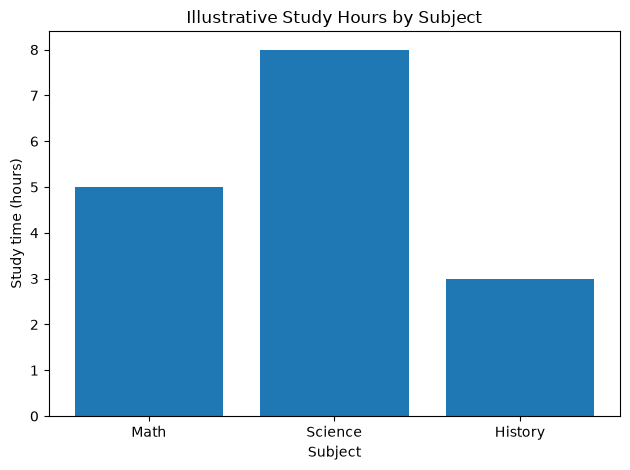

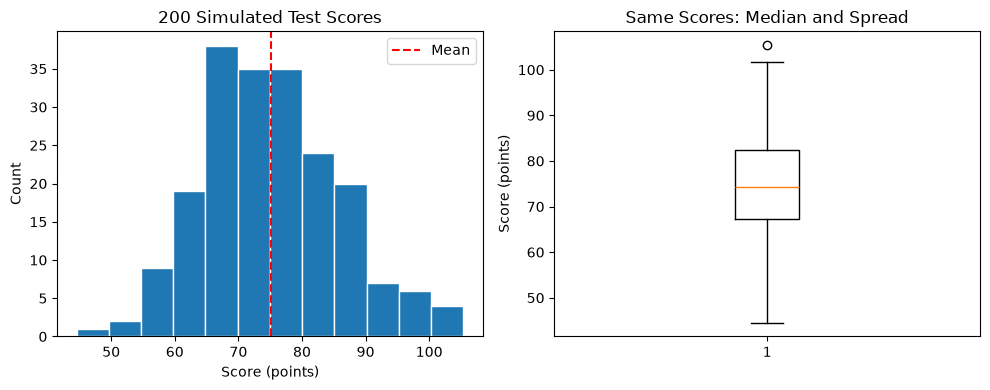

In [11]:
subjects = ['Math', 'Science', 'History']
hours_studied = [5, 8, 3]
fig, ax = plt.subplots()
ax.bar(subjects, hours_studied)
ax.set(title='Illustrative Study Hours by Subject', xlabel='Subject', ylabel='Study time (hours)')
fig.tight_layout()
fig.savefig(OUT / 'study_hours.png', dpi=150, bbox_inches='tight')
plt.show()
np.random.seed(3603)
test_scores = np.random.normal(75, 10, size=200)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(test_scores, bins=12, edgecolor='white')
axes[0].axvline(test_scores.mean(), color='red', linestyle='--', label='Mean')
axes[0].set(title='200 Simulated Test Scores', xlabel='Score (points)', ylabel='Count')
axes[0].legend()
axes[1].boxplot(test_scores)
axes[1].set(title='Same Scores: Median and Spread', ylabel='Score (points)')
fig.tight_layout()
fig.savefig(OUT / 'score_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

## Section 8: Timing Comparison and Repeated Work

In [12]:
number_list = list(range(500_000))
number_array = np.arange(500_000)
assert np.array_equal([value**2 for value in number_list], number_array**2)
loop_time = %timeit -o -n 3 -r 3 [value**2 for value in number_list]
array_time = %timeit -o -n 3 -r 3 number_array**2
print('Observed NumPy speedup:', loop_time.average/array_time.average)
def above_average(values):
    return [v for v in values if v > sum(values) / len(values)]
def above_average_fast(values):
    if not values:
        return []
    average = sum(values)/len(values)
    return [v for v in values if v > average]
values = list(range(2000))
assert above_average(values) == above_average_fast(values)
assert above_average_fast([]) == []
slow = %timeit -o -n 3 -r 3 above_average(values)
fast = %timeit -o -n 3 -r 3 above_average_fast(values)
print('Repeated-work fix speedup:', slow.average/fast.average)
# sum(values) was repeatedly scanning the entire list; compute it once.

55.7 ms ± 2.37 ms per loop (mean ± std. dev. of 3 runs, 3 loops each)
1.88 ms ± 166 μs per loop (mean ± std. dev. of 3 runs, 3 loops each)
Observed NumPy speedup: 29.606502469766106


49.3 ms ± 8.13 ms per loop (mean ± std. dev. of 3 runs, 3 loops each)
119 μs ± 10.1 μs per loop (mean ± std. dev. of 3 runs, 3 loops each)
Repeated-work fix speedup: 414.6082766899852
